In [1]:
import os, re, glob, math, shutil, zipfile
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from google.colab import drive
drive.mount('/content/drive')

ZIP     = "/content/drive/MyDrive/hasil_citra_15_zip.zip"
IN_DIR  = "/content/input"
OUT_DIR = "/content/hasil_fitur"
os.makedirs(IN_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP) as z:
    print(len(z.namelist()), "files")
    z.extractall(IN_DIR)

paths = sorted(p for p in glob.glob(f"{IN_DIR}/**/*", recursive=True)
               if p.lower().endswith((".jpg", ".jpeg", ".png")))
print("Images:", len(paths))

# Struktur: <jenis buah> fruit / Image_N / <varian>.png
# Urutan varian dibuat dari awalan nama, jadi aman untuk median15 / median31 / dst.
VARIAN_PREFIX = ["1_grayscale", "2_CS", "2_HE", "2_CLAHE",
                 "3_CS_median", "3_HE_median", "3_CLAHE_median"]

def urut_varian(v):
    v = str(v)
    for i, pre in enumerate(VARIAN_PREFIX):
        if v == pre or (pre.endswith("median") and v.startswith(pre)):
            return (i, v)
    return (99, v)

def parse_path(p):
    pp = Path(p)
    return dict(Buah=pp.parent.parent.name.replace(" fruit", ""),   # apple, banana, ...
                Sampel=pp.parent.name,                               # Image_1, Image_2, ...
                Varian=pp.stem)                                      # 1_grayscale, 3_CLAHE_median15, ...

# Cek parsing: harus muncul 9 buah dan 7 varian
meta = pd.DataFrame([parse_path(p) for p in paths])
print("\nJumlah citra per buah:");   print(meta.Buah.value_counts().sort_index().to_string())
print("\nJumlah citra per varian:"); print(meta.Varian.value_counts().sort_index().to_string())

Mounted at /content/drive
2881 files
Images: 2513

Jumlah citra per buah:
Buah
apple         280
banana        280
cherry        280
chickoo       280
grapes        280
kiwi          280
mango         273
orange        280
strawberry    280

Jumlah citra per varian:
Varian
1_grayscale         359
2_CLAHE             359
2_CS                359
2_HE                359
3_CLAHE_median15    359
3_CS_median15       359
3_HE_median15       359


In [2]:
GABOR_THETAS      = [0, 45, 90, 135]   # 0 = garis vertikal, 90 = garis horizontal
GABOR_LAMBDAS     = [4, 8]             # panjang gelombang (piksel, citra 128x128): halus & kasar
GABOR_SIGMA_RATIO = 0.56               # sigma = 0.56 * lambda
GABOR_GAMMA       = 0.5                # aspek elips envelope

def _bangun_bank():
    """Pasangan kernel kuadratur (cos & sin) untuk tiap orientasi x panjang gelombang."""
    bank = []
    for th in GABOR_THETAS:
        for lam in GABOR_LAMBDAS:
            sigma = GABOR_SIGMA_RATIO * lam
            ks = int(6 * sigma) | 1
            pair = []
            for psi in (0, np.pi / 2):
                k = cv2.getGaborKernel((ks, ks), sigma, np.deg2rad(th), lam,
                                       GABOR_GAMMA, psi, ktype=cv2.CV_32F)
                k = k - k.mean()                         # buang komponen DC
                k = k / (np.abs(k).sum() + 1e-9)         # normalisasi skala
                pair.append(k)
            bank.append((th, lam, pair[0], pair[1]))
    return bank

GABOR_BANK = _bangun_bank()
print("Jumlah filter Gabor:", len(GABOR_BANK))

# Konvolusi lewat FFT: spektrum kernel di-cache, tepi citra di-padding refleksi
_FFT_PAD = max(k.shape[0] for _, _, k, _ in GABOR_BANK) // 2 + 1
_KF_CACHE = {}

def _spektrum_kernel(N):
    if N not in _KF_CACHE:
        spec = []
        for th, lam, kr, ki in GABOR_BANK:
            pair = []
            for k in (kr, ki):
                h = k.shape[0]
                pad = np.zeros((N, N), np.float32)
                pad[:h, :h] = k
                pad = np.roll(pad, (-(h // 2), -(h // 2)), axis=(0, 1))
                pair.append(np.fft.rfft2(pad))
            spec.append(tuple(pair))
        _KF_CACHE[N] = spec
    return _KF_CACHE[N]

def _gabor_respons(gray):
    """Magnitudo respons tiap filter: sqrt(real^2 + imajiner^2)."""
    g = gray.astype(np.float32)
    H, W = g.shape
    P = _FFT_PAD
    N = cv2.getOptimalDFTSize(max(H, W) + 2 * P)
    gp = np.zeros((N, N), np.float32)
    gp[:H + 2 * P, :W + 2 * P] = cv2.copyMakeBorder(g, P, P, P, P, cv2.BORDER_REFLECT_101)
    F = np.fft.rfft2(gp)
    out = []
    for (th, lam, _, _), (Kr, Ki) in zip(GABOR_BANK, _spektrum_kernel(N)):
        re = np.fft.irfft2(F * Kr, s=(N, N))[P:P + H, P:P + W]
        im = np.fft.irfft2(F * Ki, s=(N, N))[P:P + H, P:P + W]
        out.append((th, lam, np.sqrt(re * re + im * im).astype(np.float32)))
    return out

def _gabor_peta(gray):
    """Peta respons rata-rata semua filter (untuk visualisasi)."""
    return np.mean([m for _, _, m in _gabor_respons(gray)], axis=0)

def _gabor_features(gray):
    """7 fitur Gabor: mean, std, energy, dan energi per orientasi."""
    resp = _gabor_respons(gray)
    mean_f = [m.mean() for _, _, m in resp]
    std_f  = [m.std() for _, _, m in resp]
    en_f   = [(m ** 2).mean() for _, _, m in resp]

    e_theta = {th: float(np.mean([e for (t, _, _), e in zip(resp, en_f) if t == th]))
               for th in GABOR_THETAS}

    out = {'gabor_mean':   float(np.mean(mean_f)),
           'gabor_std':    float(np.mean(std_f)),
           'gabor_energy': float(np.mean(en_f))}
    for th in GABOR_THETAS:
        out[f'gabor_e{th}'] = e_theta[th]
    return out

def _segmentasi(gray):
    _, m = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    tepi = np.concatenate([m[0], m[-1], m[:, 0], m[:, -1]])
    if tepi.mean() > 127:                 # tepi putih = latar putih -> balik
        m = cv2.bitwise_not(m)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    return cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_OPEN, k), cv2.MORPH_CLOSE, k)

def _shape_features(gray):
    m = _segmentasi(gray)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts:
        return dict(area=0, circularity=0, aspect_ratio=0, solidity=0, extent=0), m
    c = max(cnts, key=cv2.contourArea)
    area, per = cv2.contourArea(c), cv2.arcLength(c, True)
    x, y, w, h = cv2.boundingRect(c)
    hull = cv2.contourArea(cv2.convexHull(c))
    return dict(area=area / m.size,
                circularity=4 * math.pi * area / (per ** 2 + 1e-9),
                aspect_ratio=w / (h + 1e-9),
                solidity=area / (hull + 1e-9),
                extent=area / (w * h + 1e-9)), m

Jumlah filter Gabor: 8


In [3]:
def extract_features(gray):
    gray = cv2.resize(gray, (128, 128))
    gab = _gabor_features(gray)
    shape, mask = _shape_features(gray)
    return {**gab, **shape, '_gray': gray, '_mask': mask}

TEKSTUR_COLS = ['gabor_mean', 'gabor_std', 'gabor_energy'] + [f'gabor_e{t}' for t in GABOR_THETAS]
BENTUK_COLS  = ['area', 'circularity', 'aspect_ratio', 'solidity', 'extent']
FEATURE_COLS = TEKSTUR_COLS + BENTUK_COLS          # 7 Gabor + 5 bentuk = 12 fitur

ORIENT_LABEL = {0: "garis vertikal (0°)", 45: "diagonal 45°",
                90: "garis horizontal (90°)", 135: "diagonal 135°"}

def tafsir_tekstur(f, ref):
    """Relatif terhadap dataset (tertil) pada varian yang sama."""
    kunci = ['gabor_energy', 'gabor_std']
    q = ref[kunci].quantile([1/3, 2/3])
    def lvl(k, rendah, sedang, tinggi):
        v = f[k]
        return rendah if v <= q[k].iloc[0] else tinggi if v >= q[k].iloc[1] else sedang
    e = {t: float(f[f'gabor_e{t}']) for t in GABOR_THETAS}
    dom = max(e, key=e.get)
    return "; ".join([
        lvl('gabor_energy', "tekstur halus/datar", "tekstur sedang",           "tekstur kuat/berdetail"),
        lvl('gabor_std',    "respons merata",      "respons cukup bervariasi", "respons sangat bervariasi (pola/bintik lokal)"),
        f"arah terkuat: {ORIENT_LABEL[dom]}"])

def tafsir_bentuk(f):
    ar, ci, so, ex = f['aspect_ratio'], f['circularity'], f['solidity'], f['extent']
    return "; ".join([
        "memanjang horizontal" if ar > 1.25 else "memanjang vertikal" if ar < 0.75 else "proporsi hampir sama",
        "kontur mendekati lingkaran" if ci > 0.6 else "kontur agak bulat" if ci > 0.4 else "kontur tidak bulat/tidak rata",
        "bentuk cembung/utuh" if so > 0.9 else "ada lekukan" if so > 0.75 else "banyak lekukan/tonjolan",
        "mengisi hampir seluruh kotak pembatas" if ex > 0.7 else "mengisi sebagian kotak pembatas"])

## Ekstraksi semua citra

In [4]:
REP_INDEX = 0          # 0 = sampel pertama tiap buah

def _no(s):
    x = re.search(r"\d+", s)
    return int(x.group()) if x else 0

def cari_varian(prefix):
    """Semua nama varian yang diawali prefix (mis. '3_CLAHE_median' -> ['3_CLAHE_median15'])."""
    return sorted({parse_path(p)["Varian"] for p in all_paths
                   if parse_path(p)["Varian"].startswith(prefix)})

def jalankan_varian(prefix, tampil_gambar=True):
    hasil = {}
    daftar = cari_varian(prefix)
    assert daftar, f"Tidak ada varian berawalan '{prefix}'. Cek nama file."
    for v in daftar:
        print("\n" + "=" * 60 + f"\nVARIAN: {v}\n" + "=" * 60)
        paths_v = [p for p in all_paths if parse_path(p)["Varian"] == v]

        # ---- ekstraksi fitur ----
        rows, gagal = [], []
        for p in tqdm(paths_v, desc=v):
            img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
            if img is None:
                gagal.append(p); continue
            f = extract_features(img)
            rows.append(dict(**parse_path(p), **{k: f[k] for k in FEATURE_COLS}))
        df = pd.DataFrame(rows)
        df["Sampel_No"] = df["Sampel"].str.extract(r"(\d+)").astype(float)
        df = df.sort_values(["Buah", "Sampel_No"]).reset_index(drop=True)
        df["Tafsir_Tekstur"] = df.apply(lambda r: tafsir_tekstur(r, df), axis=1)
        df["Tafsir_Bentuk"]  = df.apply(tafsir_bentuk, axis=1)
        df.to_csv(f"{OUT_DIR}/fitur_{v}.csv", index=False)
        print(f"{len(df)} citra | gagal dibaca: {len(gagal)} | disimpan: fitur_{v}.csv")

        # ---- perwakilan 1 sampel per buah ----
        peta = {(parse_path(p)["Buah"], parse_path(p)["Sampel"]): p for p in paths_v}
        perwakilan = {}
        for b in sorted(df["Buah"].unique()):
            sampel_b = sorted({s for (bb, s) in peta if bb == b}, key=_no)
            perwakilan[b] = sampel_b[REP_INDEX % len(sampel_b)]
        buah_list = list(perwakilan)
        n = len(buah_list)

        feat = {b: extract_features(cv2.imread(peta[(b, perwakilan[b])], cv2.IMREAD_GRAYSCALE))
                for b in buah_list}
        gmap = {b: _gabor_peta(feat[b]['_gray']) for b in buah_list}

        if tampil_gambar:
            vmax = max(max(g.max() for g in gmap.values()), 1e-6)   # skala Gabor sama antar buah
            fig, ax = plt.subplots(3, n, figsize=(2.2 * n, 7), squeeze=False)
            for i, b in enumerate(buah_list):
                ax[0, i].imshow(feat[b]['_gray'], cmap="gray", vmin=0, vmax=255)
                ax[0, i].set_title(f"{b}\n{perwakilan[b]}", fontsize=9, fontweight="bold")
                ax[1, i].imshow(gmap[b], cmap="magma", vmin=0, vmax=vmax)
                ax[2, i].imshow(feat[b]['_mask'], cmap="gray")
                for r in range(3): ax[r, i].axis("off")
            for r, lbl in enumerate([v, "Gabor", "Mask Otsu"]):
                ax[r, 0].text(-0.08, 0.5, lbl, transform=ax[r, 0].transAxes,
                              ha="right", va="center", fontsize=8)
            fig.suptitle(f"Perwakilan per buah: {v}", y=1.0)
            plt.tight_layout(); plt.show()

        # ---- tafsir per buah ----
        for b in buah_list:
            r = df[(df.Buah == b) & (df.Sampel == perwakilan[b])].iloc[0]
            print(f"[{b} / {perwakilan[b]}] tekstur: {r['Tafsir_Tekstur']}")
            print(f"{'':{len(b) + len(perwakilan[b]) + 5}s} bentuk : {r['Tafsir_Bentuk']}")
        hasil[v] = df
    return hasil


VARIAN: 3_CLAHE_median15


3_CLAHE_median15:   0%|          | 0/359 [00:00<?, ?it/s]

359 citra | gagal dibaca: 0 | disimpan: fitur_3_CLAHE_median15.csv


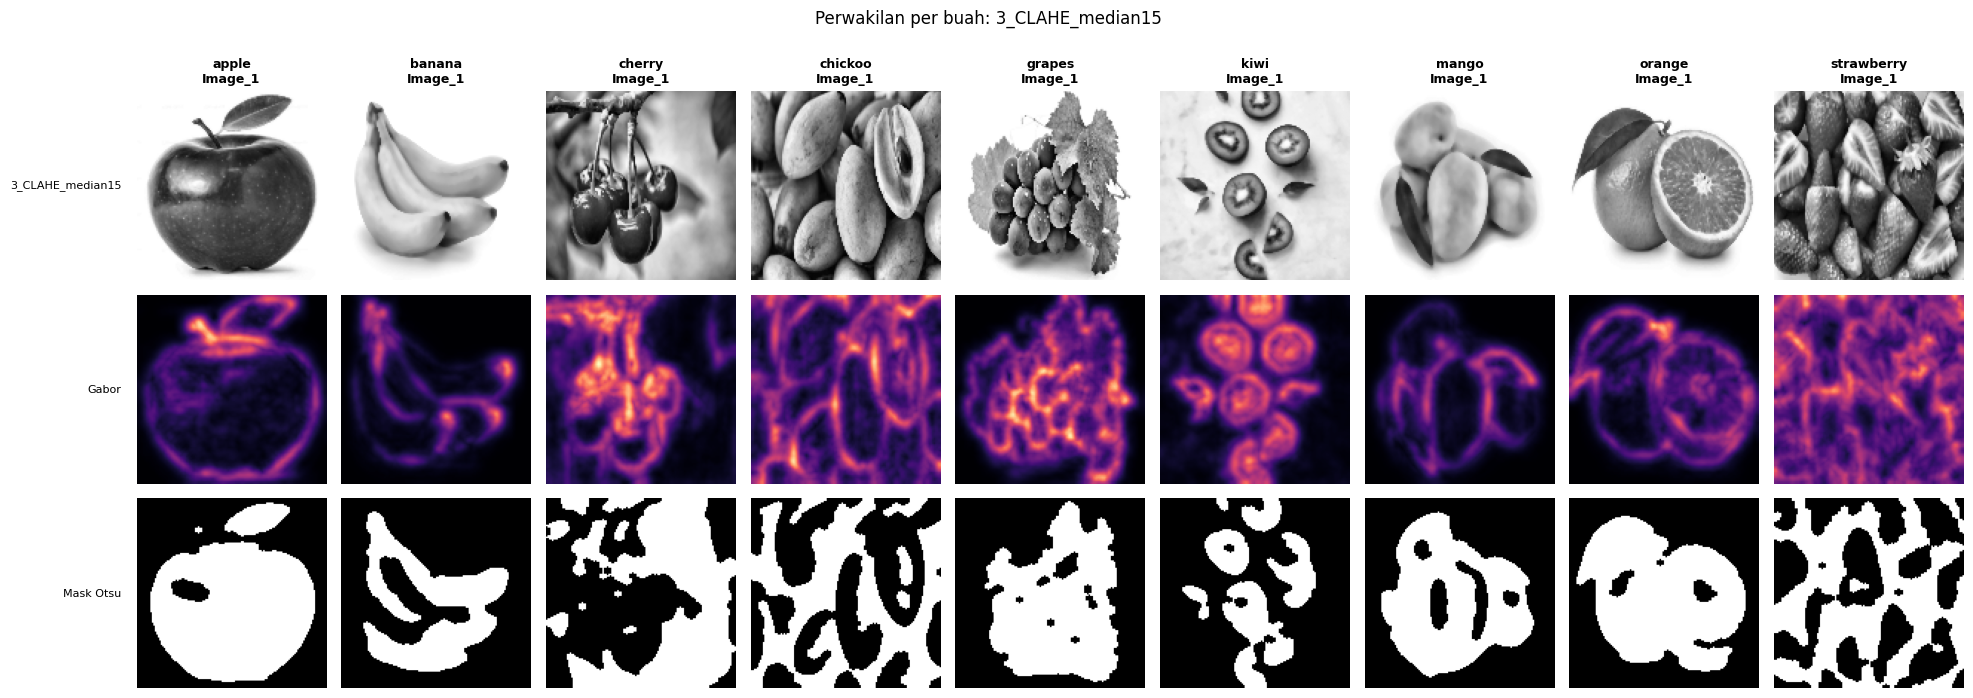

,gabor_mean,gabor_std,gabor_energy,gabor_e0,gabor_e45,gabor_e90,gabor_e135,area,circularity,aspect_ratio,solidity,extent
Buah,,,,,,,,,,,,
apple,2.3787,3.9637,25.0990,9.7945,18.8541,55.7044,16.0431,0.5020,0.8362,1.1684,0.9807,0.7799
banana,1.3927,2.5845,9.6969,16.5612,3.9781,8.5226,9.7258,0.2548,0.1244,0.9074,0.5537,0.3944
cherry,3.9894,4.8866,44.9775,97.8879,27.1397,31.7549,23.1273,0.4276,0.1364,0.8906,0.5448,0.4801
chickoo,4.5098,4.6268,50.3123,122.3459,35.1475,16.2024,27.5535,0.5391,0.1165,1.0000,0.5692,0.5391
grapes,3.9490,4.3970,37.0161,68.4833,24.7804,26.1736,28.6270,0.4435,0.3708,0.7377,0.8303,0.6618
kiwi,3.7071,4.7655,38.6310,48.6726,32.7238,39.3199,33.8078,0.0961,0.2055,0.6667,0.6758,0.4554
mango,1.6740,2.9667,13.4909,27.1876,6.8363,7.2406,12.6989,0.4386,0.6465,0.9196,0.8998,0.6230
orange,2.4981,3.6724,20.0553,21.8532,21.2312,20.0512,17.0857,0.4784,0.4551,1.0857,0.8992,0.6548
strawberry,5.3569,4.2038,49.7172,87.1460,40.3716,27.3704,43.9808,0.6137,0.0943,1.0000,0.6557,0.6137


[apple / Image_1] tekstur: tekstur sedang; respons cukup bervariasi; arah terkuat: garis horizontal (90°)
                  bentuk : proporsi hampir sama; kontur mendekati lingkaran; bentuk cembung/utuh; mengisi hampir seluruh kotak pembatas
[banana / Image_1] tekstur: tekstur halus/datar; respons merata; arah terkuat: garis vertikal (0°)
                   bentuk : proporsi hampir sama; kontur tidak bulat/tidak rata; banyak lekukan/tonjolan; mengisi sebagian kotak pembatas
[cherry / Image_1] tekstur: tekstur sedang; respons sangat bervariasi (pola/bintik lokal); arah terkuat: garis vertikal (0°)
                   bentuk : proporsi hampir sama; kontur tidak bulat/tidak rata; banyak lekukan/tonjolan; mengisi sebagian kotak pembatas
[chickoo / Image_1] tekstur: tekstur kuat/berdetail; respons sangat bervariasi (pola/bintik lokal); arah terkuat: garis vertikal (0°)
                    bentuk : proporsi hampir sama; kontur tidak bulat/tidak rata; banyak lekukan/tonjolan; mengisi sebagian 

In [5]:
all_paths = paths
df_clahe_median = jalankan_varian("3_CLAHE_median")


VARIAN: 3_CS_median15


3_CS_median15:   0%|          | 0/359 [00:00<?, ?it/s]

359 citra | gagal dibaca: 0 | disimpan: fitur_3_CS_median15.csv


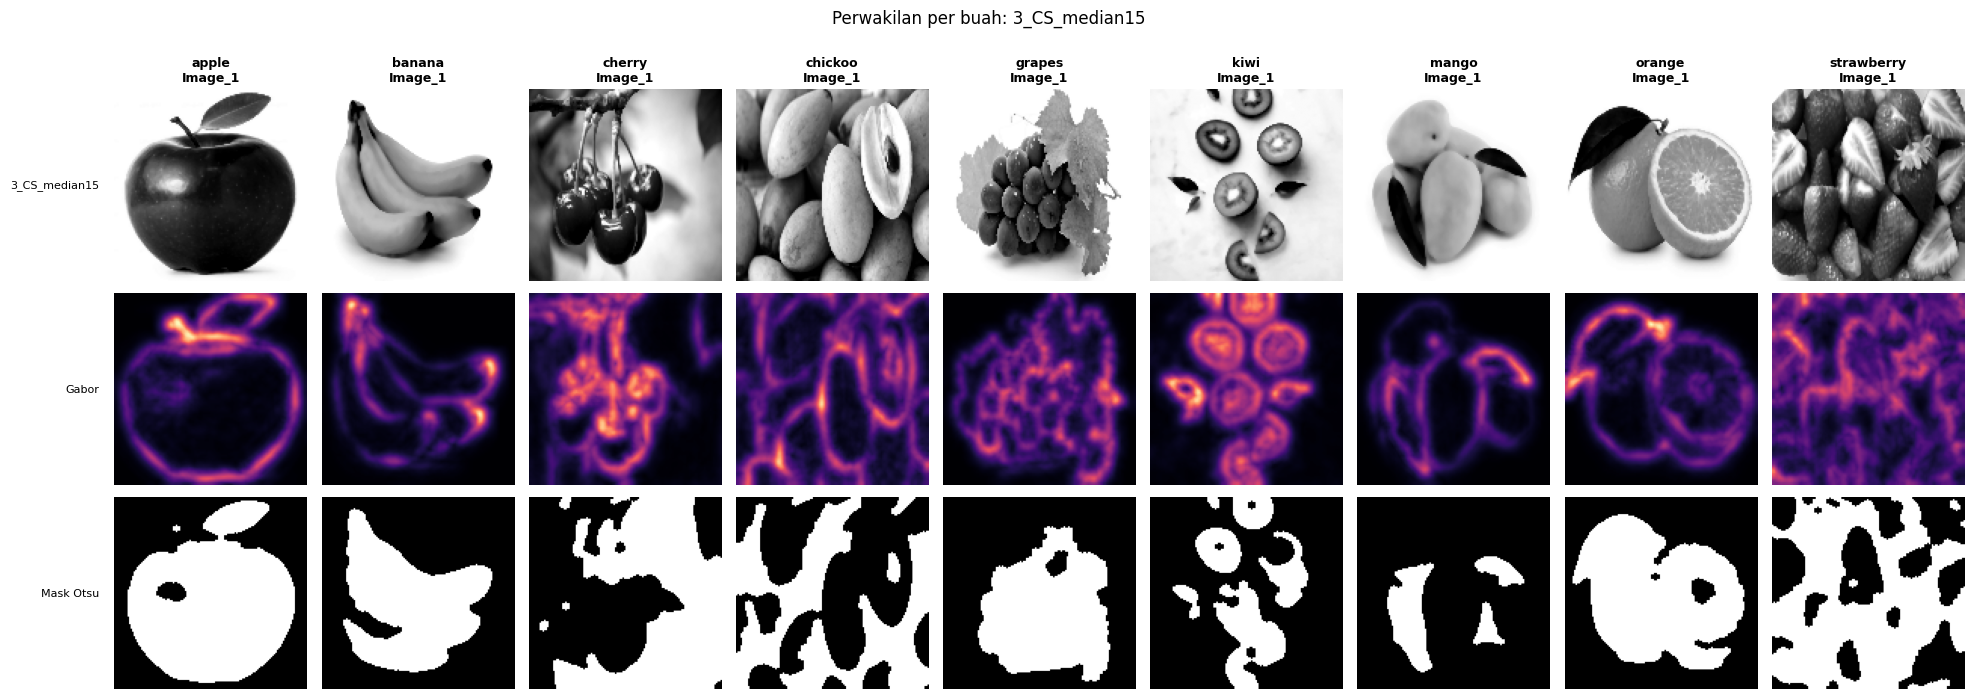

,gabor_mean,gabor_std,gabor_energy,gabor_e0,gabor_e45,gabor_e90,gabor_e135,area,circularity,aspect_ratio,solidity,extent
Buah,,,,,,,,,,,,
apple,2.3950,4.8754,33.5312,14.0735,27.2721,68.7948,23.9842,0.5451,0.5322,0.9174,0.8993,0.6649
banana,1.7053,3.3051,15.3598,27.4856,7.4607,11.0247,15.4683,0.3475,0.3353,0.9083,0.7548,0.5277
cherry,3.6375,4.8387,40.8105,85.9706,26.7962,27.7858,22.6895,0.4694,0.1972,0.8750,0.6201,0.5364
chickoo,3.7287,4.2454,39.1336,98.2758,22.8516,11.5062,23.9008,0.2115,0.1201,0.6484,0.5068,0.3261
grapes,2.9530,3.3768,21.2196,38.0514,14.6233,15.0003,17.2035,0.3769,0.5236,0.8544,0.8740,0.6813
kiwi,3.8071,5.2559,44.4602,54.2030,36.0509,46.5062,41.0807,0.1014,0.2689,0.6667,0.7106,0.4806
mango,1.6027,3.1562,14.1174,23.8465,5.4010,9.7238,17.4983,0.0777,0.4023,0.4247,0.7511,0.5627
orange,2.2798,3.8542,20.6324,18.9941,26.0891,21.6126,15.8340,0.4717,0.4303,1.1068,0.8963,0.6582
strawberry,4.2572,3.6998,34.2746,61.8488,25.2677,21.1876,28.7943,0.6960,0.2173,1.0000,0.7705,0.6960


[apple / Image_1] tekstur: tekstur sedang; respons sangat bervariasi (pola/bintik lokal); arah terkuat: garis horizontal (90°)
                  bentuk : proporsi hampir sama; kontur agak bulat; ada lekukan; mengisi sebagian kotak pembatas
[banana / Image_1] tekstur: tekstur halus/datar; respons merata; arah terkuat: garis vertikal (0°)
                   bentuk : proporsi hampir sama; kontur tidak bulat/tidak rata; ada lekukan; mengisi sebagian kotak pembatas
[cherry / Image_1] tekstur: tekstur kuat/berdetail; respons sangat bervariasi (pola/bintik lokal); arah terkuat: garis vertikal (0°)
                   bentuk : proporsi hampir sama; kontur tidak bulat/tidak rata; banyak lekukan/tonjolan; mengisi sebagian kotak pembatas
[chickoo / Image_1] tekstur: tekstur sedang; respons cukup bervariasi; arah terkuat: garis vertikal (0°)
                    bentuk : memanjang vertikal; kontur tidak bulat/tidak rata; banyak lekukan/tonjolan; mengisi sebagian kotak pembatas
[grapes / Image_1] tek

In [6]:
df_cs_median = jalankan_varian("3_CS_median")


VARIAN: 3_HE_median15


3_HE_median15:   0%|          | 0/359 [00:00<?, ?it/s]

359 citra | gagal dibaca: 0 | disimpan: fitur_3_HE_median15.csv


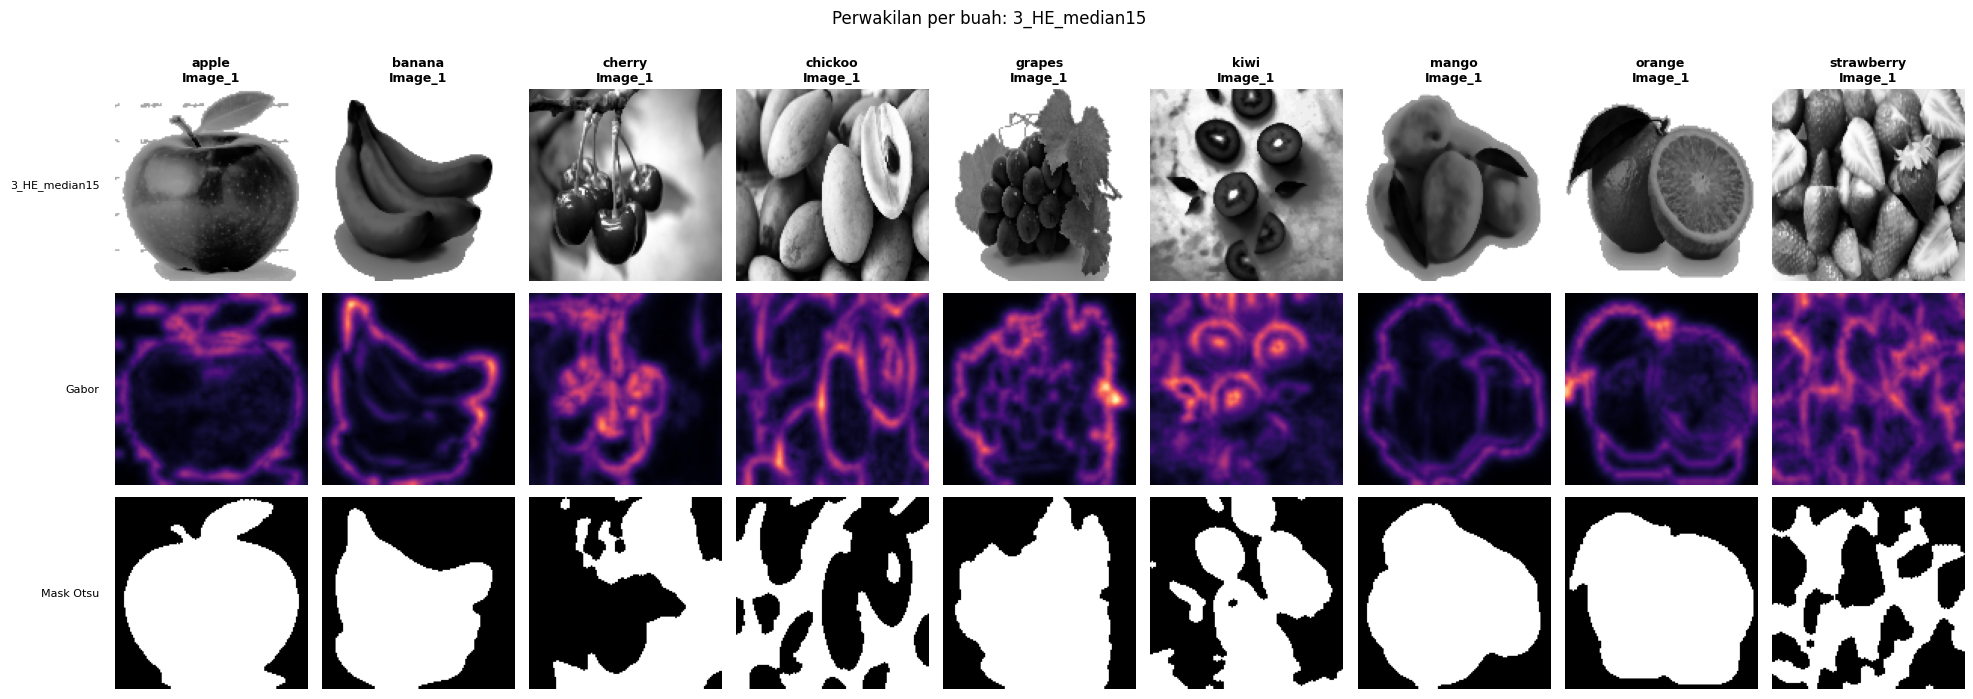

,gabor_mean,gabor_std,gabor_energy,gabor_e0,gabor_e45,gabor_e90,gabor_e135,area,circularity,aspect_ratio,solidity,extent
Buah,,,,,,,,,,,,
apple,2.5187,3.3472,20.3950,10.1036,13.1877,47.3184,10.9703,0.6228,0.5037,0.9206,0.8913,0.6981
banana,2.0407,3.8724,20.7339,35.2380,9.8227,18.3538,19.5211,0.4816,0.6024,0.8667,0.8557,0.6323
cherry,3.2028,4.2212,31.0130,63.6695,20.6397,22.1592,17.5834,0.4395,0.1810,0.8750,0.5883,0.5023
chickoo,3.8116,4.3190,40.9005,103.7268,24.5972,11.5364,23.7417,0.4589,0.0819,1.0000,0.4888,0.4589
grapes,3.1181,3.7849,25.8627,48.4684,14.0285,18.0536,22.9004,0.5710,0.5476,0.8125,0.8950,0.7028
kiwi,4.0133,4.2357,36.4947,50.8053,27.3589,30.8187,36.9958,0.3945,0.1723,0.7656,0.6688,0.5152
mango,1.8200,2.8284,11.7216,15.1843,9.7240,9.8977,12.0802,0.5839,0.7443,0.9350,0.9471,0.6763
orange,2.5086,3.6049,20.2008,24.9925,17.8226,24.5686,13.4194,0.6209,0.7070,1.0702,0.9450,0.7314
strawberry,4.6027,3.9295,39.8848,75.9592,26.1760,24.0919,33.3120,0.4478,0.0630,1.0240,0.5174,0.4586


[apple / Image_1] tekstur: tekstur halus/datar; respons merata; arah terkuat: garis horizontal (90°)
                  bentuk : proporsi hampir sama; kontur agak bulat; ada lekukan; mengisi sebagian kotak pembatas
[banana / Image_1] tekstur: tekstur halus/datar; respons cukup bervariasi; arah terkuat: garis vertikal (0°)
                   bentuk : proporsi hampir sama; kontur mendekati lingkaran; ada lekukan; mengisi sebagian kotak pembatas
[cherry / Image_1] tekstur: tekstur sedang; respons cukup bervariasi; arah terkuat: garis vertikal (0°)
                   bentuk : proporsi hampir sama; kontur tidak bulat/tidak rata; banyak lekukan/tonjolan; mengisi sebagian kotak pembatas
[chickoo / Image_1] tekstur: tekstur sedang; respons cukup bervariasi; arah terkuat: garis vertikal (0°)
                    bentuk : proporsi hampir sama; kontur tidak bulat/tidak rata; banyak lekukan/tonjolan; mengisi sebagian kotak pembatas
[grapes / Image_1] tekstur: tekstur sedang; respons cukup bervariasi

In [7]:
df_he_median = jalankan_varian("3_HE_median")

In [8]:
nama_df = ("df_clahe", "df_clahe_median", "df_cs", "df_cs_median", "df_he", "df_he_median")
semua = [d for nm in nama_df if nm in globals() for d in globals()[nm].values()]
df_semua = pd.concat(semua, ignore_index=True)      # kolom Varian sudah ada di tiap df
df_semua.to_csv(f"{OUT_DIR}/fitur_semua_varian.csv", index=False)

## Download hasil

In [9]:
zip_out = shutil.make_archive("/content/hasil_fitur", "zip", OUT_DIR)
print("Zip dibuat:", zip_out, f"({os.path.getsize(zip_out) / 1e6:.2f} MB)")
try:
    from google.colab import files
    files.download(zip_out)
except ImportError:
    display(__import__("IPython.display", fromlist=["FileLink"]).FileLink(zip_out))

Zip dibuat: /content/hasil_fitur.zip (0.26 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>